# Titanic outlier analysis with OutlierTrimmer

`OutlierTrimmer` removes rows that are outside limits learned from a statistical rule. Unlike capping, it does not change an extreme value; it excludes the entire passenger row from the transformed dataset.

This notebook demonstrates IQR trimming and quantile trimming on Titanic numeric variables, reports how many passengers are removed, and checks whether the removed group differs in survival or passenger class.

## When is trimming appropriate?

Trimming may be useful when records are known data errors, outside the population of interest, or so influential that they distort the intended model. A genuine high fare or large family is still a valid passenger observation, so removal should be justified and audited. Because trimming changes row count and sample composition, report the number and identity of removed rows.

In [1]:
import importlib.util,subprocess,sys
packages={"numpy":"numpy","pandas":"pandas","matplotlib":"matplotlib","seaborn":"seaborn","sklearn":"scikit-learn","feature_engine":"feature-engine"}
missing=[pkg for module,pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install",*missing])
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from feature_engine.outliers import OutlierTrimmer
sns.set_theme(style="whitegrid",context="notebook")

## 1. Load Titanic data and prepare numeric predictors

We use age, fare, siblings/spouses, and parents/children aboard. Missing values are imputed with training medians before fitting the trimmer. Passenger class is excluded because it is a categorical class code, and post-event fields are excluded to avoid leakage.

,age,fare,sibsp,parch,survived
count,1046.00,1308.00,1309.00,1309.00,1309.00
mean,29.88,33.30,0.50,0.39,0.38
std,14.41,51.76,1.04,0.87,0.49
min,0.17,0.00,0.00,0.00,0.00
25%,21.00,7.90,0.00,0.00,0.00
50%,28.00,14.45,0.00,0.00,0.00
75%,39.00,31.28,1.00,0.00,1.00
max,80.00,512.33,8.00,9.00,1.00


,missing_count
age,263
fare,1
sibsp,0
parch,0


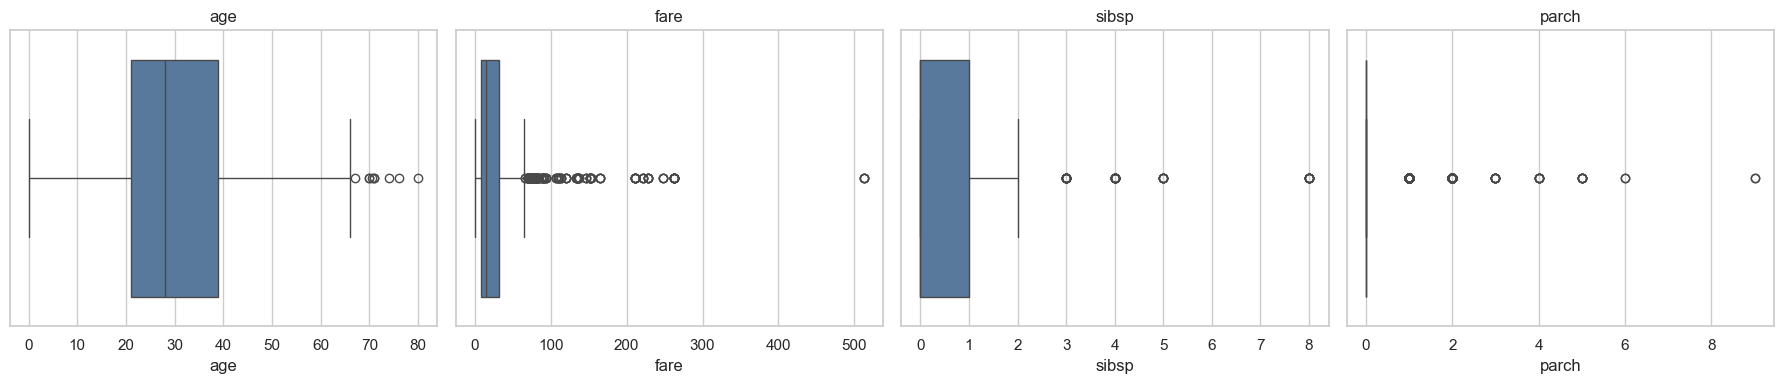

In [2]:
paths=[Path("titanic.csv"),Path("../outliers/titanic.csv"),Path("feature-engineering/outliers/titanic.csv"),Path("../encoding/titanic.csv")]
path=next((p for p in paths if p.exists()),None)
if path is None: raise FileNotFoundError("Could not find Titanic titanic.csv")
data=pd.read_csv(path,na_values=["?"])
numeric_features=["age","fare","sibsp","parch"]
for col in numeric_features+["survived"]: data[col]=pd.to_numeric(data[col],errors="coerce")
display(data[numeric_features+["survived"]].describe().round(2))
display(data[numeric_features].isna().sum().rename("missing_count").to_frame())
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,col in zip(axes,numeric_features): sns.boxplot(x=data[col],ax=ax,color="#4C78A8"); ax.set_title(col)
plt.tight_layout(); plt.show()

## 2. Split before learning the trimming limits

The IQR rule uses Q1 − 1.5×IQR and Q3 + 1.5×IQR. The limits are learned from training passengers and then applied unchanged to test passengers. This keeps the held-out distribution from influencing preprocessing. `parch` is retained for exploration but excluded from IQR trimming because its discrete count distribution has too little variation for Feature-engine's IQR check.

In [3]:
X=data[numeric_features].copy(); y=data["survived"].astype(int)
outlier_features=["age","fare","sibsp"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.30,random_state=0,stratify=y)
imputer=SimpleImputer(strategy="median")
X_train=pd.DataFrame(imputer.fit_transform(X_train[outlier_features]),columns=outlier_features,index=X_train.index)
X_test=pd.DataFrame(imputer.transform(X_test[outlier_features]),columns=outlier_features,index=X_test.index)
trimmer=OutlierTrimmer(capping_method="iqr",tail="both",fold=1.5,variables=outlier_features)
trimmer.fit(X_train)
train_trimmed=trimmer.transform(X_train); test_trimmed=trimmer.transform(X_test)
limits=pd.DataFrame({"lower_limit":pd.Series(trimmer.left_tail_caps_),"upper_limit":pd.Series(trimmer.right_tail_caps_)})
display(limits)
print(f"Training passengers: {len(X_train):,} -> {len(train_trimmed):,}")
print(f"Test passengers: {len(X_test):,} -> {len(test_trimmed):,}")

,lower_limit,upper_limit
age,2.125,55.1250
fare,-27.173,66.3438
sibsp,-1.500,2.5000


Training passengers: 916 -> 721
Test passengers: 393 -> 310


## 3. Identify removed passengers

A row is removed when it is an outlier in at least one selected variable. We use index differences to identify removed passengers and compare their survival and passenger-class composition with retained rows.

In [4]:
removed_train=X_train.index.difference(train_trimmed.index)
removed_test=X_test.index.difference(test_trimmed.index)
print("Removed train rows:",len(removed_train),f"({len(removed_train)/len(X_train):.1%})")
print("Removed test rows:",len(removed_test),f"({len(removed_test)/len(X_test):.1%})")
display(X_train.loc[removed_train].head(12))
removed_outcomes=data.loc[removed_train,["survived","pclass"]]
retained_outcomes=data.loc[train_trimmed.index,["survived","pclass"]]
comparison=pd.DataFrame({"group":["Removed","Retained"],"passengers":[len(removed_outcomes),len(retained_outcomes)],"survival_rate":[removed_outcomes.survived.mean(),retained_outcomes.survived.mean()],"mean_class":[removed_outcomes.pclass.mean(),retained_outcomes.pclass.mean()]})
display(comparison.round(3))

Removed train rows: 195 (21.3%)
Removed test rows: 83 (21.1%)


,age,fare,sibsp
0,29.0000,211.3375,0.0
1,0.9167,151.5500,1.0
2,2.0000,151.5500,1.0
3,30.0000,151.5500,1.0
4,25.0000,151.5500,1.0
6,63.0000,77.9583,1.0
9,71.0000,49.5042,0.0
10,47.0000,227.5250,1.0
11,18.0000,227.5250,1.0
12,24.0000,69.3000,0.0


,group,passengers,survival_rate,mean_class
0,Removed,195,0.508,1.646
1,Retained,721,0.348,2.494


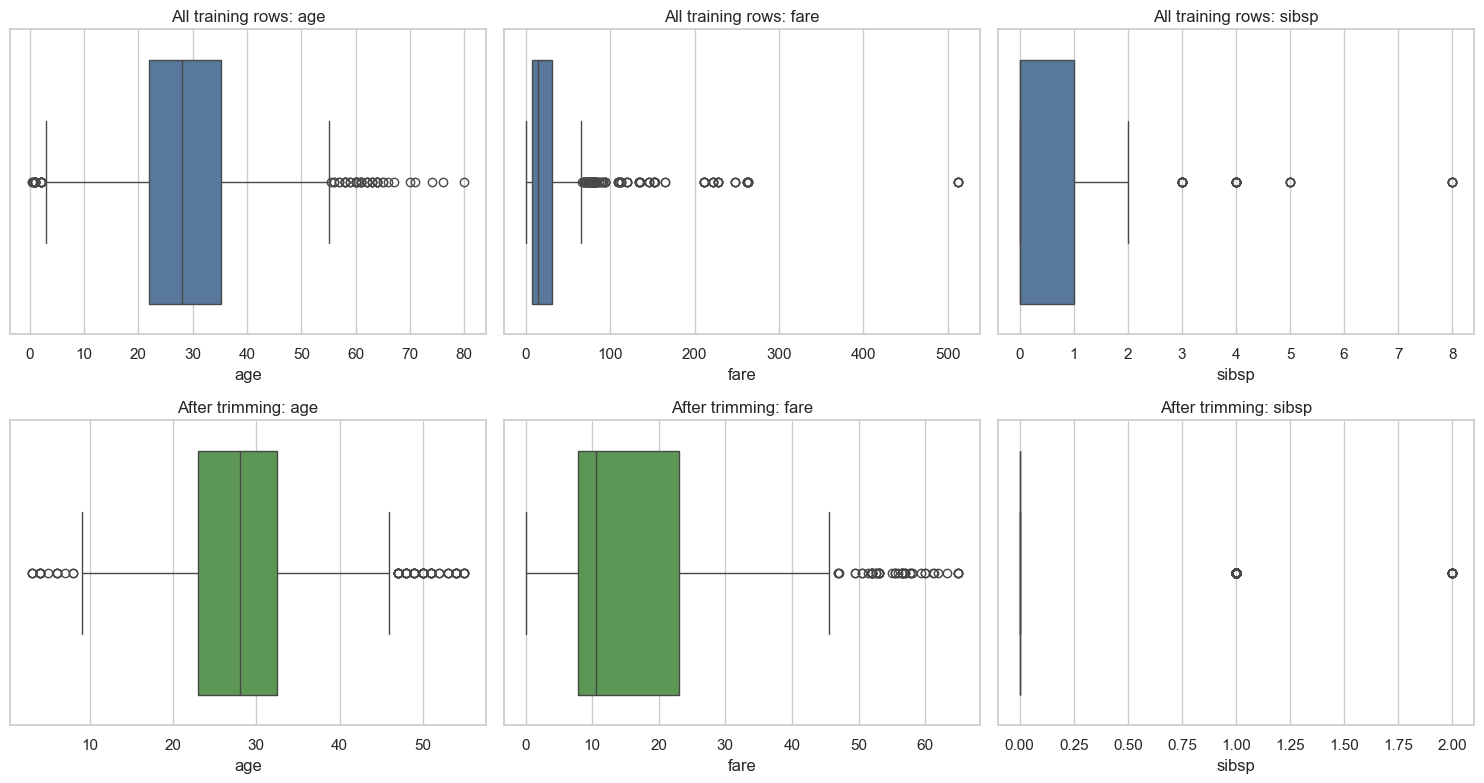

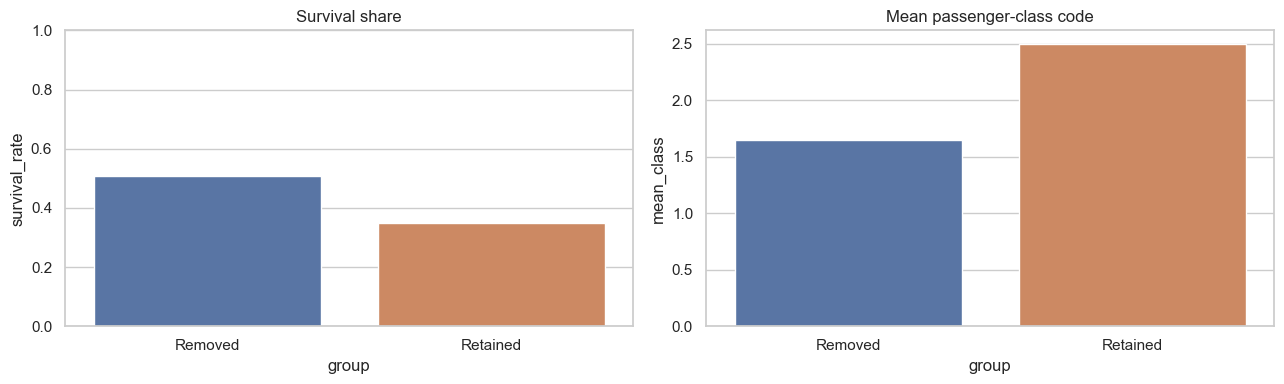

In [5]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
for i,col in enumerate(outlier_features):
    sns.boxplot(x=X_train[col],ax=axes[0,i],color="#4C78A8"); axes[0,i].set_title(f"All training rows: {col}")
    sns.boxplot(x=train_trimmed[col],ax=axes[1,i],color="#54A24B"); axes[1,i].set_title(f"After trimming: {col}")
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.barplot(data=comparison,x="group",y="survival_rate",hue="group",legend=False,ax=axes[0]); axes[0].set_ylim(0,1); axes[0].set_title("Survival share")
sns.barplot(data=comparison,x="group",y="mean_class",hue="group",legend=False,ax=axes[1]); axes[1].set_title("Mean passenger-class code")
plt.tight_layout(); plt.show()

## 4. Compare IQR and quantile trimming

IQR boundaries depend on the spread of the middle half of the data. Quantile trimming removes a planned proportion from each tail. These methods can remove different passengers, so inspect the result rather than treating the choice as interchangeable.

In [7]:
quantile_trimmer=OutlierTrimmer(capping_method="quantiles",tail="both",fold=.05,variables=outlier_features)
quantile_trimmer.fit(X_train)
train_quantile=quantile_trimmer.transform(X_train)
comparison_methods=pd.DataFrame({"method":["IQR (1.5 × IQR)","Quantiles (5% each tail)"],"rows_retained":[len(train_trimmed),len(train_quantile)]})
comparison_methods["rows_removed"]=len(X_train)-comparison_methods["rows_retained"]
display(comparison_methods)
display(pd.DataFrame({"IQR lower":pd.Series(trimmer.left_tail_caps_),"IQR upper":pd.Series(trimmer.right_tail_caps_),"Quantile lower":pd.Series(quantile_trimmer.left_tail_caps_),"Quantile upper":pd.Series(quantile_trimmer.right_tail_caps_)}))

,method,rows_retained,rows_removed
0,IQR (1.5 × IQR),721,195
1,Quantiles (5% each tail),730,186


,IQR lower,IQR upper,Quantile lower,Quantile upper
age,2.125,55.1250,8.000,55.0000
fare,-27.173,66.3438,7.225,133.8625
sibsp,-1.500,2.5000,0.000,2.0000


## Summary and cautions

`OutlierTrimmer` changes the sample by deleting passengers. That can alter survival rates and class composition, as the audit table demonstrates. Use it only with a defensible population rule, fit it on training data only, document removed rows, and compare with Winsorizer or ArbitraryOutlierCapper before deciding that deletion is appropriate.